# ParasiteID - Nits vs Other image classifier

Binary image classification comparing **MobileNetV3Large**, **EfficientNetB0**, and **ResNet50V2**.

* Positive class: **nits** (head-lice eggs) - folders `nits/`, `nits/Hair nits/`, `nits/Hair nits train/`
* Negative class: **other** - folders `Dandruff/`, `Healthy Scalp/`, `lice/`

Transfer learning (ImageNet weights), two-phase training (freeze head -> fine-tune top layers),
trained on CPU at 224x224. Run the cells top to bottom.

## 1. Environment & configuration

In [1]:
import os, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
print("CPUs:", os.cpu_count())

# --- Reproducibility ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# --- CPU threads ---
N_THREADS = os.cpu_count() or 8
tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
tf.config.threading.set_inter_op_parallelism_threads(N_THREADS)

# --- Config ---
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_HEAD = 15
EPOCHS_FINETUNE = 10
FINETUNE_LAYERS = 30
AUTOTUNE = tf.data.AUTOTUNE

DATA_DIR = Path(".")
OUT_MODELS = Path("models")
OUT_RESULTS = Path("results")
OUT_LOGS = Path("logs")
for d in (OUT_MODELS, OUT_RESULTS, OUT_LOGS):
    d.mkdir(exist_ok=True)

CLASS_DIRS = {
    "nits":  ["nits"],
    "other": ["Dandruff", "Healthy Scalp", "lice"],
}

MODELS = {
    "MobileNetV3Large": dict(ctor=tf.keras.applications.MobileNetV3Large,
                             preprocess=tf.keras.applications.mobilenet_v3.preprocess_input),
    "EfficientNetB0":   dict(ctor=tf.keras.applications.EfficientNetB0,
                             preprocess=tf.keras.applications.efficientnet.preprocess_input),
    "ResNet50V2":       dict(ctor=tf.keras.applications.ResNet50V2,
                             preprocess=tf.keras.applications.resnet_v2.preprocess_input),
}
print("Models registered:", list(MODELS))

I0000 00:00:1792963279.320865    1061 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792963279.325569    1061 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792963279.889829    1061 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792963281.278007    1061 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
CPUs: 16
Models registered: ['MobileNetV3Large', 'EfficientNetB0', 'ResNet50V2']


E0000 00:00:1792963282.417932    1061 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792963282.418177    1677 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792963282.435520    1061 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## 2. Index the images

Recursively scan each source folder, validate/read each image, map it to its binary label, and remove content duplicates.

In [2]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".gif", ".bmp"}

def iter_images(root):
    root = Path(root)
    if root.is_file():
        if root.suffix.lower() in IMG_EXTS:
            yield root
        return
    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMG_EXTS:
            yield p

def file_hash(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def probe(path):
    """Return (width, height) or (None, None) if the image cannot be read."""
    try:
        with Image.open(path) as im:
            w, h = im.size
            im.convert("RGB")
        return w, h
    except Exception:
        return None, None

records = []
for label, folders in CLASS_DIRS.items():
    for folder in folders:
        n = 0
        for p in iter_images(DATA_DIR / folder):
            w, h = probe(p)
            if w is None:
                print("  skip (unreadable):", p)
                continue
            records.append({"filepath": str(p), "label": label, "width": w, "height": h})
            n += 1
        print(f"{label:5s} <- {folder:25s} {n:5d} images")

df = pd.DataFrame(records)
print("\nRaw images:", len(df))

df["hash"] = df["filepath"].map(file_hash)
before = len(df)
df = df.drop_duplicates("hash").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate images -> {len(df)} unique")

df["y"] = (df["label"] == "nits").astype(int)
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
df.head()

nits  <- nits                        999 images
other <- Dandruff                    898 images
other <- Healthy Scalp               770 images
other <- lice                          5 images

Raw images: 2672
Removed 0 duplicate images -> 2672 unique


,filepath,label,width,height,hash,y
0,Healthy Scalp/Healthy Scalp train/1000663714_j...,other,224,224,68daf830a745a7b39924a995b0538ce546cfd0c87c4438...,0
1,Dandruff/Dandruff train/dandruff-hair_93_jpg.r...,other,224,224,44b33304640b14c4234d55012bfdff68beb534af221f24...,0
2,Dandruff/Dandruff train/seborrheic_dermatitis_...,other,224,224,a2aa47c0498615a85bff9ec605c047dc4898e0f3ccc4d0...,0
3,Dandruff/Dandruff train/seborrheic_dermatitis_...,other,224,224,46b48f53fa415669537e9b34b9d92c7484879670bed2d7...,0
4,Dandruff/Dandruff train/seborrheic_dermatitis_...,other,224,224,b83148f653246128993bcfee966ec57c08353bcff10bda...,0


## 3. Quick EDA

label
other    1673
nits      999
Name: count, dtype: int64 



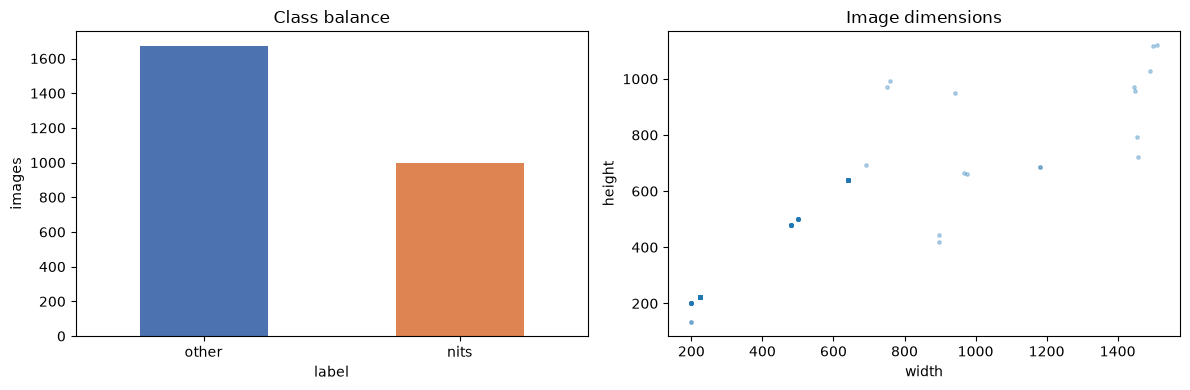

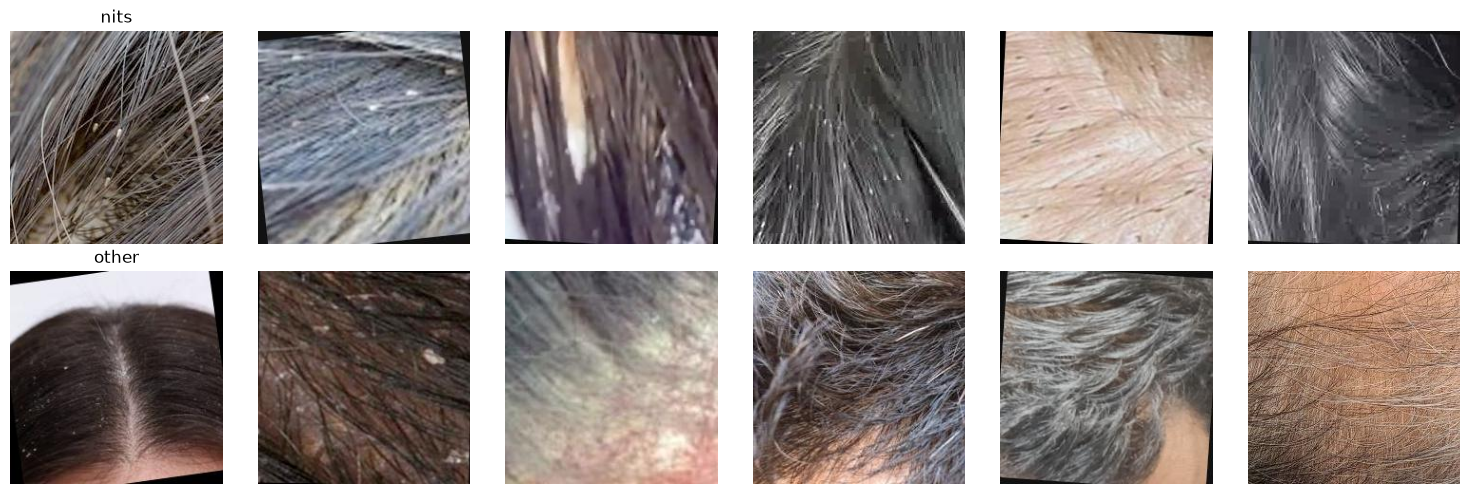

In [3]:
print(df["label"].value_counts(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["label"].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Class balance"); axes[0].set_ylabel("images"); axes[0].tick_params(axis="x", rotation=0)
axes[1].scatter(df["width"], df["height"], s=6, alpha=0.3)
axes[1].set_xlabel("width"); axes[1].set_ylabel("height"); axes[1].set_title("Image dimensions")
plt.tight_layout(); plt.savefig(OUT_RESULTS / "eda.png", dpi=120); plt.show()

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row, label in enumerate(["nits", "other"]):
    subset = df[df["label"] == label].sample(6, random_state=SEED)
    for col, (_, r) in enumerate(subset.iterrows()):
        ax = axes[row, col]
        ax.imshow(Image.open(r["filepath"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        ax.axis("off")
        if col == 0:
            ax.set_title(label, fontsize=12)
plt.tight_layout(); plt.show()

## 4. Train / validation / test split

Stratified 70/15/15 on the binary label. The same split (saved to `results/splits.json`) is used by every model so the comparison is fair.

In [4]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("train:", len(train_df), "val:", len(val_df), "test:", len(test_df))
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name:5s}", d["label"].value_counts().to_dict())

splits = {name: d["filepath"].tolist() for name, d in
          [("train", train_df), ("val", val_df), ("test", test_df)]}
(OUT_RESULTS / "splits.json").write_text(json.dumps(splits, indent=2))

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["y"].values)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class_weight:", class_weight)

train: 1870 val: 401 test: 401
  train {'other': 1171, 'nits': 699}
  val   {'other': 251, 'nits': 150}
  test  {'other': 251, 'nits': 150}
class_weight: {0: 0.798462852263023, 1: 1.3376251788268956}


## 5. `tf.data` pipelines

Decode -> resize -> augment (train only) -> model-specific preprocessing. Each model needs its own preprocessing function, so pipelines are built per model inside `make_ds`.

In [5]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="augmentation")

def decode_img(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.ensure_shape(img, [None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return tf.cast(img, tf.float32), label

def make_ds(paths, labels, preprocess, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_img, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

## 6. Model factory

Shared head: `GlobalAveragePooling2D -> Dropout -> Dense(1, sigmoid)` on top of each frozen ImageNet backbone.

In [6]:
def build_model(name):
    base = MODELS[name]["ctor"](include_top=False, weights="imagenet",
                                input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name=name), base

def compile_model(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall"),
                 tf.keras.metrics.AUC(name="auc")],
    )

## 7. Train (two-phase transfer learning)

Phase 1 freezes the backbone and trains the head. Phase 2 unfreezes the top layers and fine-tunes at a low LR. Same callbacks, epochs, augmentation and class weights for every model.

In [7]:
def plot_history(name, hist):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric in zip(axes, ["accuracy", "loss", "auc"]):
        ax.plot(hist["epoch"], hist[metric], label="train")
        if f"val_{metric}" in hist:
            ax.plot(hist["epoch"], hist[f"val_{metric}"], label="val")
        ax.axvline(EPOCHS_HEAD + 0.5, color="gray", ls=":", lw=1)
        ax.set_title(f"{name}: {metric}"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

def train_model(name, verbose=1):
    tf.keras.backend.clear_session()
    print(f"\n{'=' * 60}\nTraining {name}\n{'=' * 60}")
    model, base = build_model(name)
    preprocess = MODELS[name]["preprocess"]

    train_ds = make_ds(train_df["filepath"].values, train_df["y"].values, preprocess, True)
    val_ds = make_ds(val_df["filepath"].values, val_df["y"].values, preprocess, False)

    ckpt_path = str(OUT_MODELS / f"{name}.keras")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_auc",
                                           mode="max", save_best_only=True, verbose=verbose),
        tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                         patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=3, min_lr=1e-7, verbose=verbose),
    ]

    t0 = time.time()
    compile_model(model, 1e-3)
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                      class_weight=class_weight, callbacks=callbacks, verbose=verbose)

    base.trainable = True
    for layer in base.layers[:-FINETUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    compile_model(model, 1e-5)
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
                      class_weight=class_weight, callbacks=callbacks, verbose=verbose)
    elapsed = time.time() - t0

    h1 = pd.DataFrame(hist1.history); h1["phase"] = "head"
    h2 = pd.DataFrame(hist2.history); h2["phase"] = "finetune"
    hist = pd.concat([h1, h2], ignore_index=True)
    hist.insert(0, "epoch", np.arange(1, len(hist) + 1))
    hist.to_csv(OUT_RESULTS / f"{name}_history.csv", index=False)

    val_auc = max(list(hist1.history.get("val_auc", [0.0])) +
                  list(hist2.history.get("val_auc", [0.0])))
    meta = dict(model=name,
                params=int(model.count_params()),
                size_mb=round(os.path.getsize(ckpt_path) / 1e6, 1),
                train_seconds=round(elapsed, 1),
                val_auc=float(val_auc),
                epochs_ran=int(len(hist)))
    (OUT_RESULTS / f"{name}_meta.json").write_text(json.dumps(meta, indent=2))
    print(f"{name}: {elapsed / 60:.1f} min | {meta['params'] / 1e6:.2f}M params "
          f"| {meta['size_mb']} MB | best val_auc={meta['val_auc']:.4f}")
    return model, hist

### Run training

Set `MODELS_TO_TRAIN` to one model (faster) or all three for the full comparison. Checkpoints and histories are written per model, so you can stop and resume.


Training MobileNetV3Large
Epoch 1/15


/home/jackm/liceDetection/ParasiteID/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7032 - auc: 0.7724 - loss: 0.5788 - precision: 0.5885 - recall: 0.6853
Epoch 1: val_auc improved from None to 0.92944, saving model to models/MobileNetV3Large.keras

Epoch 1: finished saving model to models/MobileNetV3Large.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.7032 - auc: 0.7724 - loss: 0.5788 - precision: 0.5885 - recall: 0.6853 - val_accuracy: 0.8554 - val_auc: 0.9294 - val_loss: 0.3734 - val_precision: 0.7771 - val_recall: 0.8600 - learning_rate: 0.0010
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8572 - auc: 0.9203 - loss: 0.3609 - precision: 0.7827 - recall: 0.8555
Epoch 2: val_auc improved from 0.92944 to 0.95420, saving model to models/MobileNetV3Large.keras

Epoch 2: finished saving model to models/MobileNetV3Large.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - accuracy: 0.8572 - auc: 0.9203 - loss: 0.3609 - precision: 0.7827 - recall: 0.8555 - val_accuracy: 0.8828 - val_auc: 

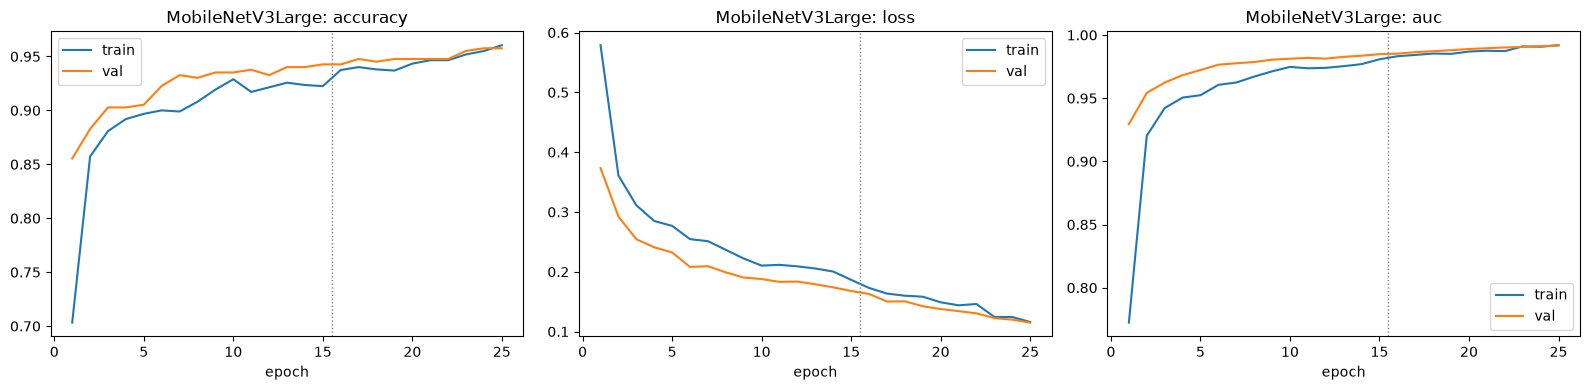


Training EfficientNetB0
Epoch 1/15


/home/jackm/liceDetection/ParasiteID/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.7797 - auc: 0.8439 - loss: 0.5100 - precision: 0.6963 - recall: 0.7282
Epoch 1: val_auc improved from None to 0.91958, saving model to models/EfficientNetB0.keras

Epoch 1: finished saving model to models/EfficientNetB0.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 17s 237ms/step - accuracy: 0.7797 - auc: 0.8439 - loss: 0.5100 - precision: 0.6963 - recall: 0.7282 - val_accuracy: 0.8728 - val_auc: 0.9196 - val_loss: 0.3762 - val_precision: 0.8235 - val_recall: 0.8400 - learning_rate: 0.0010
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.8893 - auc: 0.9337 - loss: 0.3401 - precision: 0.8417 - recall: 0.8670
Epoch 2: val_auc improved from 0.91958 to 0.94141, saving model to models/EfficientNetB0.keras

Epoch 2: finished saving model to models/EfficientNetB0.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 12s 190ms/step - accuracy: 0.8893 - auc: 0.9337 - loss: 0.3401 - precision: 0.8417 - recall: 0.8670 - val_accuracy: 0.8803 - val_auc: 0.9414 

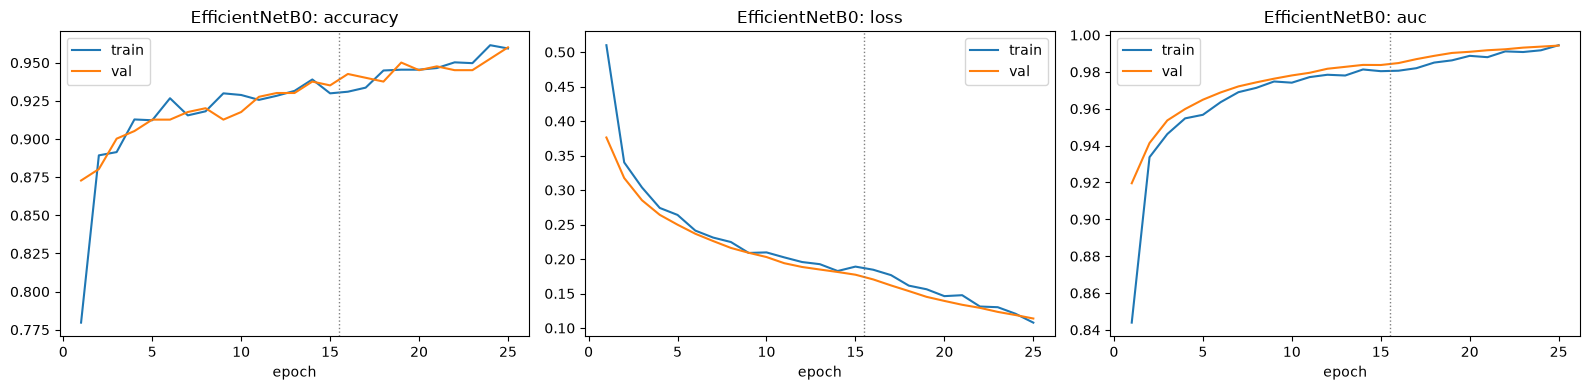


Training ResNet50V2
Epoch 1/15


/home/jackm/liceDetection/ParasiteID/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.7615 - auc: 0.8432 - loss: 0.4894 - precision: 0.6469 - recall: 0.7969
Epoch 1: val_auc improved from None to 0.95483, saving model to models/ResNet50V2.keras

Epoch 1: finished saving model to models/ResNet50V2.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 20s 298ms/step - accuracy: 0.7615 - auc: 0.8432 - loss: 0.4894 - precision: 0.6469 - recall: 0.7969 - val_accuracy: 0.8928 - val_auc: 0.9548 - val_loss: 0.2845 - val_precision: 0.8452 - val_recall: 0.8733 - learning_rate: 0.0010
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.8652 - auc: 0.9397 - loss: 0.3153 - precision: 0.7826 - recall: 0.8856
Epoch 2: val_auc improved from 0.95483 to 0.96854, saving model to models/ResNet50V2.keras

Epoch 2: finished saving model to models/ResNet50V2.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 16s 260ms/step - accuracy: 0.8652 - auc: 0.9397 - loss: 0.3153 - precision: 0.7826 - recall: 0.8856 - val_accuracy: 0.9077 - val_auc: 0.9685 - val_loss: 0.23

In [ ]:
MODEL_TO_RUN = "MobileNetV3Large"     # quickest on CPU
MODELS_TO_TRAIN = list(MODELS)

for name in MODELS_TO_TRAIN:
    _, hist = train_model(name)
    plot_history(name, hist)

## 8. Evaluate on the held-out test set

In [ ]:
def evaluate_model(name):
    model = tf.keras.models.load_model(OUT_MODELS / f"{name}.keras")
    preprocess = MODELS[name]["preprocess"]
    test_ds = make_ds(test_df["filepath"].values, test_df["y"].values, preprocess, False)

    y_true = test_df["y"].values
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    print(f"\n=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=["other", "nits"], digits=4))

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    acc = (tp + tn) / cm.sum()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    auc = roc_auc_score(y_true, y_prob)
    print(f"acc={acc:.4f} | nits precision={prec:.4f} recall={rec:.4f} "
          f"f1={f1:.4f} | auc={auc:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
    axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
    axes[0].set_xticklabels(["other", "nits"]); axes[0].set_yticklabels(["other", "nits"])
    axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
    axes[0].set_title(f"{name} confusion matrix")

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    axes[1].plot(fpr, tpr, label=f"AUC={auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
    axes[1].set_title(f"{name} ROC"); axes[1].legend()
    plt.tight_layout(); plt.savefig(OUT_RESULTS / f"{name}_eval.png", dpi=120); plt.show()

    result = dict(model=name, test_acc=acc, test_precision=prec, test_recall=rec,
                  test_f1=f1, test_auc=auc)
    (OUT_RESULTS / f"{name}_eval.json").write_text(json.dumps(result, indent=2))
    return result

In [ ]:
for name in MODELS_TO_TRAIN:
    evaluate_model(name)

NameError: name 'MODELS_TO_TRAIN' is not defined

## 9. Model comparison

In [ ]:
def collect_results():
    rows = []
    for name in MODELS:
        meta_p = OUT_RESULTS / f"{name}_meta.json"
        eval_p = OUT_RESULTS / f"{name}_eval.json"
        if meta_p.exists() and eval_p.exists():
            rows.append({**json.loads(meta_p.read_text()),
                         **json.loads(eval_p.read_text())})
    return pd.DataFrame(rows)

summary = collect_results()
if summary.empty:
    print("No evaluated models yet - train and evaluate at least one model above.")
else:
    summary = summary.sort_values("test_f1", ascending=False).reset_index(drop=True)
    cols = ["model", "params", "size_mb", "train_seconds", "val_auc",
            "test_acc", "test_precision", "test_recall", "test_f1", "test_auc"]
    display(summary[cols])
    summary.to_csv(OUT_RESULTS / "model_comparison.csv", index=False)
    best = summary.iloc[0]
    print(f"\nBest model by test F1: {best['model']} "
          f"(F1={best['test_f1']:.4f}, AUC={best['test_auc']:.4f})")

,model,params,size_mb,train_seconds,val_auc,test_acc,test_precision,test_recall,test_f1,test_auc
0,ResNet50V2,23566849,210.4,483.5,0.999974,0.995012,1.000000,0.986667,0.993289,0.998964
1,EfficientNetB0,4050852,28.9,352.2,0.995086,0.977556,0.979592,0.960000,0.969697,0.997981
2,MobileNetV3Large,2997313,25.4,237.0,0.992603,0.972569,0.948387,0.980000,0.963934,0.998353



Best model by test F1: ResNet50V2 (F1=0.9933, AUC=0.9990)


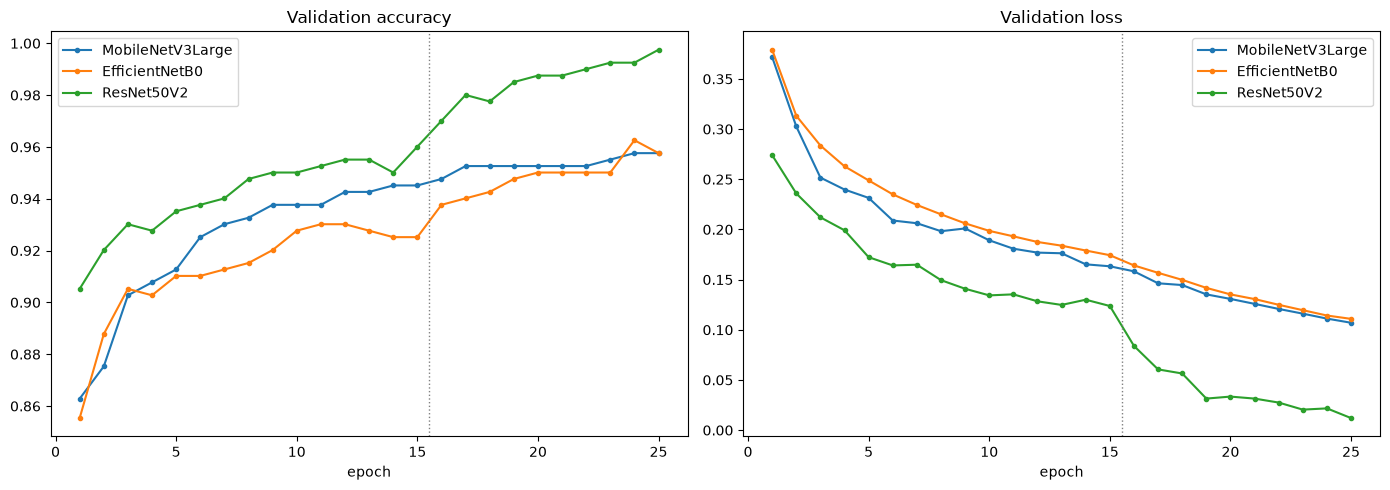

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in MODELS:
    p = OUT_RESULTS / f"{name}_history.csv"
    if not p.exists():
        continue
    h = pd.read_csv(p)
    axes[0].plot(h["epoch"], h["val_accuracy"], marker="o", ms=3, label=name)
    axes[1].plot(h["epoch"], h["val_loss"], marker="o", ms=3, label=name)
for ax, title in zip(axes, ["Validation accuracy", "Validation loss"]):
    ax.axvline(EPOCHS_HEAD + 0.5, color="gray", ls=":", lw=1)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_RESULTS / "comparison_curves.png", dpi=120); plt.show()

## 10. Out-of-distribution check: nits on a comb

`nits on comb images/` holds 96 frames (1080x1920) of nits on a comb that were **never**
trained on - and they look nothing like the training distribution (studio macro shots of nits
on hair). This section checks whether the saved models still recognise nits in the wild.

Positives alone are not enough to judge a model: a model that answered "nits" to every image
would score 100%. So the evaluation set is balanced:

* **positives** - the 96 comb frames (expected label: nits)
* **negatives** - held-out "other" images (dandruff / healthy scalp / lice) from the test
  split, filtered to remove images that are near-duplicates of training images, then sampled
  to match the positives 1:1

Two things to keep in mind when reading the numbers:

* The comb frames are portrait, every negative is square. Aspect ratio would leak the label,
  so the section reports a framing-matched variant (centre crop) alongside the native
  pipeline (squash) and a letterboxed variant.
* The 96 positives are frames of a **single video**, so they are one sample, not 96.


In [ ]:
# --- Build the evaluation set: comb nits (positives) + held-out "other" (negatives) ---

NEW_POS_DIR = Path("nits on comb images")
N_NEGATIVES = 96            # 1:1 with the comb frames
NEG_SEED = 42
NEAR_DUP_MAX_DIST = 8       # dhash distance at/below which two images count as near-duplicates


def dhash(path, size=8):
    """64-bit perceptual hash (difference hash) used for near-duplicate detection."""
    with Image.open(path) as im:
        g = im.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()


def hamming(a, b):
    return int((a != b).sum())


splits = json.loads((OUT_RESULTS / "splits.json").read_text())
train_paths = [p for p in splits["train"] if Path(p).exists()]
test_other = [p for p in splits["test"]
              if Path(p).parts[0] != "nits" and Path(p).exists()]

print(f"hashing {len(train_paths)} training images for near-duplicate filtering ...")
train_hashes = [dhash(p) for p in train_paths]

clean_negatives, dropped = [], 0
for p in test_other:
    h = dhash(p)
    if min(hamming(h, t) for t in train_hashes) <= NEAR_DUP_MAX_DIST:
        dropped += 1
    else:
        clean_negatives.append(p)

print(f"held-out 'other' candidates   : {len(test_other)}")
print(f"  dropped (near-dup of train)  : {dropped}")
print(f"  clean negatives available    : {len(clean_negatives)}")

rng = np.random.default_rng(NEG_SEED)
n_neg = min(N_NEGATIVES, len(clean_negatives))
negatives = sorted(str(p) for p in rng.choice(clean_negatives, size=n_neg, replace=False))
positives = sorted(str(p) for p in NEW_POS_DIR.glob("*.jpg")) if NEW_POS_DIR.exists() else []

if not positives:
    raise RuntimeError(f"No images found in '{NEW_POS_DIR}' - cannot run the comb evaluation.")

eval_df = pd.DataFrame(
    [{"filepath": p, "y": 1, "group": "comb_nits"} for p in positives]
    + [{"filepath": p, "y": 0, "group": Path(p).parts[0]} for p in negatives]
)
print(f"\nevaluation set: {len(positives)} positives (comb) + {len(negatives)} negatives")
display(eval_df["group"].value_counts())

# the comb frames must not overlap the training data either
comb_min_dist = min(min(hamming(dhash(p), t) for t in train_hashes) for p in positives)
print(f"min dhash distance, comb frames vs training images: {comb_min_dist} "
      f"(0 = identical, <= {NEAR_DUP_MAX_DIST} = near-duplicate)")


hashing 1870 training images for near-duplicate filtering ...
held-out 'other' candidates   : 251
  dropped (near-dup of train)  : 80
  clean negatives available    : 171

evaluation set: 96 positives (comb) + 96 negatives


group
comb_nits        96
Dandruff         50
Healthy Scalp    45
lice              1
Name: count, dtype: int64

In [ ]:
# --- Run every saved model over the evaluation set ---

RESIZE_MODES = ("squash", "centercrop", "letterbox")
THRESHOLD = 0.5
_MODEL_CACHE = {}


def decode_img_mode(path, mode="squash"):
    """Decode + resize like the training pipeline, with selectable framing."""
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.ensure_shape(img, [None, None, 3])
    if mode == "squash":                       # native training behaviour
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    elif mode == "centercrop":                 # framing-matched: crop to square first
        h, w = tf.shape(img)[0], tf.shape(img)[1]
        s = tf.minimum(h, w)
        img = tf.image.crop_to_bounding_box(img, (h - s) // 2, (w - s) // 2, s, s)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    elif mode == "letterbox":                  # fit the whole frame, pad to square
        img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE)
    else:
        raise ValueError(f"unknown mode: {mode}")
    return tf.cast(img, tf.float32)


def get_model(model_name):
    if model_name not in _MODEL_CACHE:
        _MODEL_CACHE[model_name] = tf.keras.models.load_model(OUT_MODELS / f"{model_name}.keras")
    return _MODEL_CACHE[model_name]


def predict_paths(model_name, paths, mode="squash"):
    """Return one probability per path (1.0 = nits)."""
    model = get_model(model_name)
    preprocess = MODELS[model_name]["preprocess"]
    ds = tf.data.Dataset.from_tensor_slices(list(paths))
    ds = ds.map(lambda p: decode_img_mode(p, mode), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).cache()
    ds = ds.map(lambda x: preprocess(x), num_parallel_calls=AUTOTUNE)
    return model.predict(ds.prefetch(AUTOTUNE), verbose=0).ravel()


y_true = eval_df["y"].values
rows, probs_all = [], {}
per_image = eval_df.copy()
for name in MODELS:
    ckpt = OUT_MODELS / f"{name}.keras"
    if not ckpt.exists():
        print(f"skip {name}: no checkpoint at {ckpt}")
        continue
    for mode in RESIZE_MODES:
        t0 = time.time()
        probs = predict_paths(name, eval_df["filepath"].tolist(), mode)
        probs_all[(name, mode)] = probs
        if mode == "squash":
            per_image[f"prob_{name}"] = probs
        y_pred = (probs >= THRESHOLD).astype(int)
        tp = int(((y_true == 1) & (y_pred == 1)).sum())
        fn = int(((y_true == 1) & (y_pred == 0)).sum())
        fp = int(((y_true == 0) & (y_pred == 1)).sum())
        tn = int(((y_true == 0) & (y_pred == 0)).sum())
        rows.append({
            "model": name, "resize": mode,
            "nits_detected": tp, "nits_total": tp + fn,
            "detect_pct": 100.0 * tp / max(tp + fn, 1),
            "false_nits": fp, "other_total": fp + tn,
            "false_pct": 100.0 * fp / max(fp + tn, 1),
            "accuracy": (tp + tn) / len(y_true),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "recall": tp / (tp + fn) if tp + fn else 0.0,
            "f1": (2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0,
            "mean_prob_nits": float(probs[y_true == 1].mean()),
            "mean_prob_other": float(probs[y_true == 0].mean()),
            "seconds": round(time.time() - t0, 1),
        })
        print(f"  {name:16s} {mode:11s} done in {rows[-1]['seconds']:.1f}s")

summary = pd.DataFrame(rows)
if not summary.empty:
    ref = {}
    for name in MODELS:
        p = OUT_RESULTS / f"{name}_eval.json"
        if p.exists():
            ref[name] = json.loads(p.read_text())
    summary["test_f1"] = summary["model"].map(lambda m: ref.get(m, {}).get("test_f1", np.nan))
    summary["test_acc"] = summary["model"].map(lambda m: ref.get(m, {}).get("test_acc", np.nan))
    display(summary[["model", "resize", "nits_detected", "nits_total", "detect_pct",
                     "false_nits", "other_total", "false_pct", "accuracy", "precision",
                     "recall", "f1", "test_f1"]])


In [ ]:
# --- Save the raw numbers next to the other results ---

OUT_RESULTS.mkdir(exist_ok=True)
if not summary.empty:
    summary.to_csv(OUT_RESULTS / "comb_nits_summary.csv", index=False)
    (OUT_RESULTS / "comb_nits_summary.json").write_text(summary.to_json(orient="records", indent=2))
    per_image.to_csv(OUT_RESULTS / "comb_nits_predictions.csv", index=False)
    print("wrote comb_nits_summary.csv / comb_nits_summary.json / comb_nits_predictions.csv")


In [ ]:
# --- Visualise: confusion matrices, metric bars, and a labelled frame grid ---

PRIMARY_MODE = "squash"      # native pipeline, matches training


if not summary.empty:
    names = summary["model"].drop_duplicates().tolist()

    fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4.2))
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        cm = confusion_matrix(y_true, (probs_all[(name, PRIMARY_MODE)] >= THRESHOLD).astype(int))
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["other", "nits"]); ax.set_yticklabels(["other", "nits"])
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.set_title(name)
    plt.suptitle(f"Confusion matrices - comb frames + held-out others (resize: {PRIMARY_MODE})")
    plt.tight_layout()
    plt.savefig(OUT_RESULTS / "comb_nits_confusion.png", dpi=120)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    modes = list(RESIZE_MODES)
    width = 0.8 / len(modes)
    for ax, metric, title in zip(axes, ["detect_pct", "false_pct"],
                                 ["Comb nits detected (%)", "False \"nits\" on others (%)"]):
        for k, mode in enumerate(modes):
            sub = summary[summary["resize"] == mode].set_index("model")
            vals = [sub.loc[n, metric] if n in sub.index else np.nan for n in names]
            x = np.arange(len(names)) + (k - (len(modes) - 1) / 2) * width
            ax.bar(x, vals, width=width, label=mode)
        ax.set_xticks(np.arange(len(names))); ax.set_xticklabels(names, fontsize=9)
        ax.set_ylabel("%"); ax.set_title(title); ax.legend(title="resize")
    plt.tight_layout()
    plt.savefig(OUT_RESULTS / "comb_nits_metrics.png", dpi=120)
    plt.show()

    step = max(1, len(positives) // 24)
    show = positives[::step][:24]
    fig, axes = plt.subplots(4, 6, figsize=(18, 12))
    for ax, path in zip(axes.flat, show):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.axis("off")
        labels, all_ok = [], True
        for name in names:
            p = float(probs_all[(name, PRIMARY_MODE)][positives.index(path)])
            labels.append(f"{name}: {p:.2f}")
            all_ok = all_ok and p >= THRESHOLD
        ax.set_title("\n".join(labels), fontsize=9)
        for s in ax.spines.values():
            s.set_color("limegreen" if all_ok else "crimson")
            s.set_linewidth(3)
    plt.suptitle("Comb frames - probability of nits (green = every model detected it)")
    plt.tight_layout()
    plt.savefig(OUT_RESULTS / "comb_nits_grid.png", dpi=120)
    plt.show()


In [ ]:
# --- Verdict ---

if summary.empty:
    print("No models evaluated.")
else:
    primary = summary[summary["resize"] == PRIMARY_MODE].set_index("model")
    ranked = primary.sort_values(["detect_pct", "f1"], ascending=False)
    print(f"Comb evaluation (resize: {PRIMARY_MODE})")
    for name in ranked.index:
        r = ranked.loc[name]
        print(f"  {name:16s} detected {r['nits_detected']}/{r['nits_total']} nits "
              f"({r['detect_pct']:.1f}%), {r['false_nits']}/{r['other_total']} false positives "
              f"({r['false_pct']:.1f}%), acc {r['accuracy']:.3f}, F1 {r['f1']:.3f}"
              f"   | held-out test F1 {r['test_f1']:.3f}")
    print(f"\nBest on the comb frames: {ranked.index[0]}")

    in_dist = summary.groupby("model")["test_f1"].first()
    for name in primary.index:
        lo = summary[summary["model"] == name]["detect_pct"].min()
        hi = summary[summary["model"] == name]["detect_pct"].max()
        gap = in_dist.get(name, np.nan) - primary.loc[name, "f1"]
        if not np.isnan(gap) and gap > 0.05:
            print(f"Warning: {name} has the best held-out test F1 "
                  f"({in_dist[name]:.3f}) but only detects "
                  f"{primary.loc[name, 'detect_pct']:.1f}% of the comb frames "
                  f"({lo:.0f}-{hi:.0f}% across resize modes, F1 {primary.loc[name, 'f1']:.3f}). "
                  f"It is the most over-fitted to the training distribution.")